# Importancia de variables

Antecedente. En el A/B se probaron tres paquetes de columnas de la consulta: F0 (forma del texto), F1 (texto más intención) y F2 (F1 más BM25). F1 fue el que mejor predijo candidate_strategy.

Qué se hace aquí. Se toma ese paquete F1 y se mide qué columnas pesan más, con un bosque aleatorio: impureza, permutación, SHAP y estabilidad entre pliegues.

Nota. F1 es el nombre del paquete de columnas. F1 macro, si aparece, es la métrica de clasificación.

1. Datos y columnas usadas.
2. Modelo de árbol para importancias.
3. Importancia por ganancia (impurity).
4. Importancia por permutación.
5. SHAP (TreeSHAP).
6. Estabilidad entre pliegues.
7. Interpretación y conclusión.

Modelo: RandomForestClassifier.
Validación: cinco pliegues estratificados, semilla 42.
Etiqueta: candidate_strategy.


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path("..").resolve()
DATA_PATH = ROOT / "data" / "processed" / "features" / "consultas_features.csv"
LOG_DIR = ROOT / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_SPLITS = 5
TARGET = "candidate_strategy"
TOP_N = 10


## 1. Datos y columnas usadas

Fuente: data/processed/features/consultas_features.csv.

Se usan las columnas del paquete F1:

- texto: longitud, interrogaciones, negación, condición, comparación, caso personal;
- intención: familia léxica, número de familias, marcas de cálculo, regla, tiempo, entidades, categoría de intención.

No entran las columnas BM25 del paquete F2.
El catálogo completo está en docs/feature_engineering.md.


In [2]:
df = pd.read_csv(DATA_PATH)
y = df[TARGET].astype(str)

F1_NUM = [
    "query_length_chars",
    "query_length_words",
    "question_mark_count",
    "has_multiple_questions",
    "contains_negation",
    "contains_condition",
    "contains_comparison",
    "contains_personal_case",
    "n_intent_families",
    "requires_multiple_sources_rule",
    "requires_personal_context",
    "requires_calculation",
    "requires_rule_validation",
    "requires_temporal_reasoning",
    "contains_academic_entity",
    "contains_administrative_entity",
]
F1_CAT = ["intent_category"]

X = df[F1_NUM + F1_CAT]
print("filas:", len(df))
print("columnas F1:", len(F1_NUM) + len(F1_CAT))
print(y.value_counts().sort_index().to_string())


filas: 196
columnas F1: 17
candidate_strategy
A1    125
A3     27
A5     44


## 2. Modelo de árbol para importancias

Se usa un bosque aleatorio porque la clase muestra importancias por impureza en árboles.
El preprocesamiento (one-hot de intent_category) se ajusta solo en entrenamiento dentro de cada pliegue cuando se mide estabilidad.
Para el ranking global se ajusta el pipeline en todo el conjunto F1, solo como diagnóstico descriptivo del piloto.


In [3]:
prep = ColumnTransformer(
    [
        ("num", "passthrough", F1_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), F1_CAT),
    ]
)

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1,
)

pipe = Pipeline([("prep", prep), ("modelo", rf)])
pipe.fit(X, y)

# nombres de features después del one-hot
ohe = pipe.named_steps["prep"].named_transformers_["cat"]
cat_names = list(ohe.get_feature_names_out(F1_CAT))
feature_names = F1_NUM + cat_names
print("features expandidas:", len(feature_names))

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
f1_cv = cross_val_score(pipe, X, y, cv=cv, scoring="f1_macro")
print(f"F1 macro CV: {f1_cv.mean():.3f} ± {f1_cv.std():.3f}")


features expandidas: 23


F1 macro CV: 0.553 ± 0.086


## 3. Importancia por ganancia (impurity)

Suma de la reducción de impureza cuando la columna entra en una división.
Sirve para un ranking rápido. No prueba causalidad.


,feature,importancia_impurity
0,query_length_chars,0.371675
1,query_length_words,0.197345
2,contains_personal_case,0.072670
3,contains_administrative_entity,0.037172
4,contains_academic_entity,0.035504
5,n_intent_families,0.035429
6,intent_category_otro,0.034446
7,requires_rule_validation,0.032568
8,contains_condition,0.032352
9,requires_personal_context,0.023641


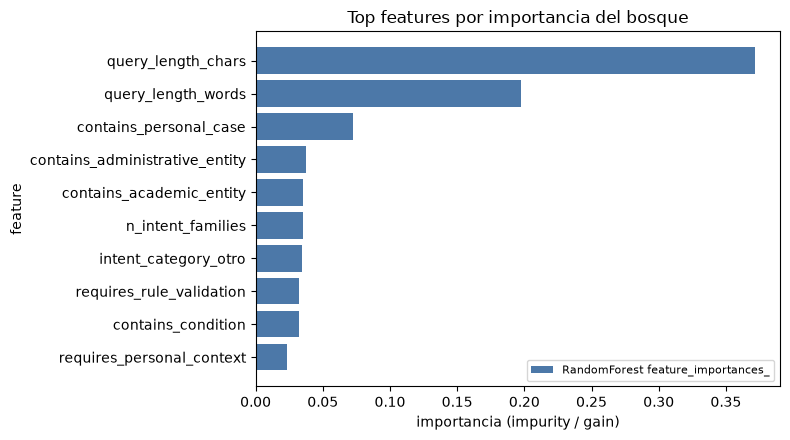

In [4]:
imp_gain = pd.Series(
    pipe.named_steps["modelo"].feature_importances_,
    index=feature_names,
).sort_values(ascending=False)

tabla_gain = imp_gain.head(TOP_N).rename("importancia_impurity").reset_index()
tabla_gain.columns = ["feature", "importancia_impurity"]
display(tabla_gain)

fig, ax = plt.subplots(figsize=(8, 4.5))
top = imp_gain.head(TOP_N).iloc[::-1]
ax.barh(top.index, top.values, color="#4C78A8")
ax.set_xlabel("importancia (impurity / gain)")
ax.set_ylabel("feature")
ax.set_title("Top features por importancia del bosque")
ax.legend(["RandomForest feature_importances_"], loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana7_importancia_impurity.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Importancia por permutación

Se baraja cada columna en validación y se mira cuánto cae el F1 macro.
Es modelo-agnóstica y suele ser más estable que solo la impureza.


,feature,caida_f1_media,caida_f1_std
0,contains_personal_case,0.077148,0.043904
1,query_length_chars,0.069323,0.030708
2,intent_category,0.058818,0.036729
3,n_intent_families,0.043466,0.018626
4,requires_multiple_sources_rule,0.017823,0.008422
5,has_multiple_questions,0.000000,0.000000
6,contains_comparison,0.000000,0.000000
7,question_mark_count,0.000000,0.000000
8,requires_calculation,-0.000600,0.002616
9,contains_negation,-0.003000,0.005197


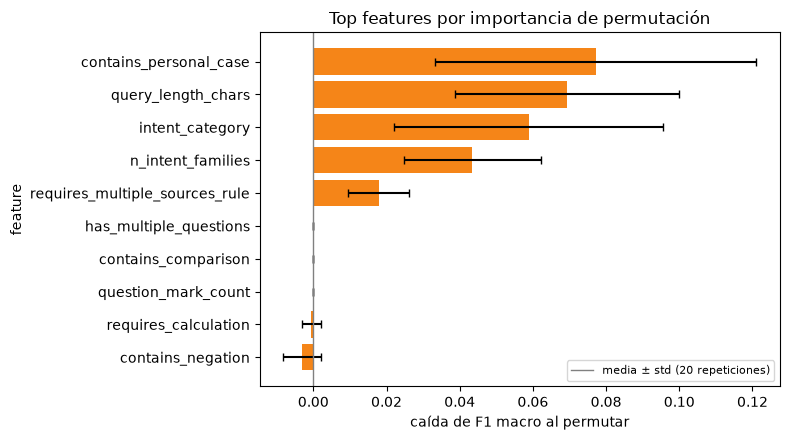

In [5]:
# holdout estratificado fijo para permutación (mismo seed)
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
pipe_perm = Pipeline(
    [
        (
            "prep",
            ColumnTransformer(
                [
                    ("num", "passthrough", F1_NUM),
                    (
                        "cat",
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        F1_CAT,
                    ),
                ]
            ),
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                random_state=SEED,
                class_weight="balanced",
                n_jobs=-1,
            ),
        ),
    ]
)
pipe_perm.fit(X_tr, y_tr)

# permutación sobre columnas originales (antes del one-hot), más legible
perm = permutation_importance(
    pipe_perm,
    X_te,
    y_te,
    scoring="f1_macro",
    n_repeats=20,
    random_state=SEED,
    n_jobs=-1,
)

imp_perm = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
imp_perm_std = pd.Series(perm.importances_std, index=X.columns)

tabla_perm = pd.DataFrame(
    {
        "feature": imp_perm.head(TOP_N).index,
        "caida_f1_media": imp_perm.head(TOP_N).values,
        "caida_f1_std": imp_perm_std.loc[imp_perm.head(TOP_N).index].values,
    }
)
display(tabla_perm)

fig, ax = plt.subplots(figsize=(8, 4.5))
top_p = imp_perm.head(TOP_N).iloc[::-1]
err = imp_perm_std.loc[top_p.index]
ax.barh(top_p.index, top_p.values, xerr=err.values, capsize=3, color="#F58518")
ax.set_xlabel("caída de F1 macro al permutar")
ax.set_ylabel("feature")
ax.set_title("Top features por importancia de permutación")
ax.axvline(0, color="gray", linewidth=1)
ax.legend(["media ± std (20 repeticiones)"], loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana7_importancia_permutacion.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. SHAP (TreeSHAP)

SHAP reparte la predicción entre features: un valor positivo empuja hacia la clase; uno negativo la aleja.
En bosques se usa TreeSHAP. Aquí se resume el efecto medio absoluto (ranking) y un summary plot de la clase mayoritaria A1.


,feature,mean_abs_shap
0,query_length_chars,0.109306
1,contains_personal_case,0.073674
2,query_length_words,0.051312
3,intent_category_otro,0.033364
4,contains_administrative_entity,0.032338
5,n_intent_families,0.031630
6,requires_rule_validation,0.020600
7,contains_academic_entity,0.017175
8,intent_category_pagos,0.015345
9,contains_condition,0.013702


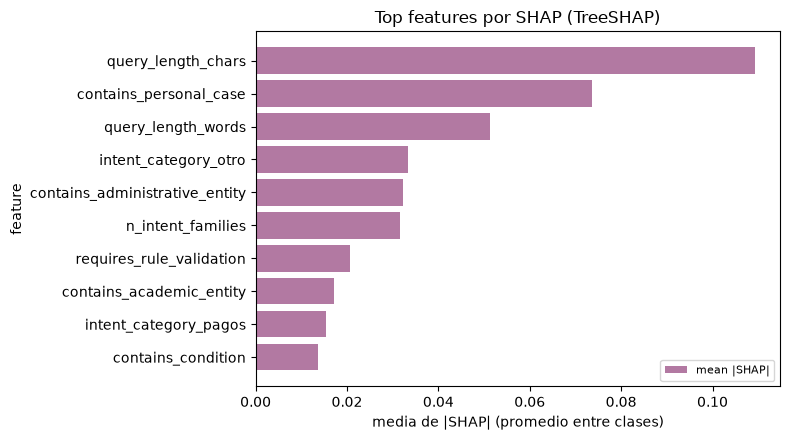

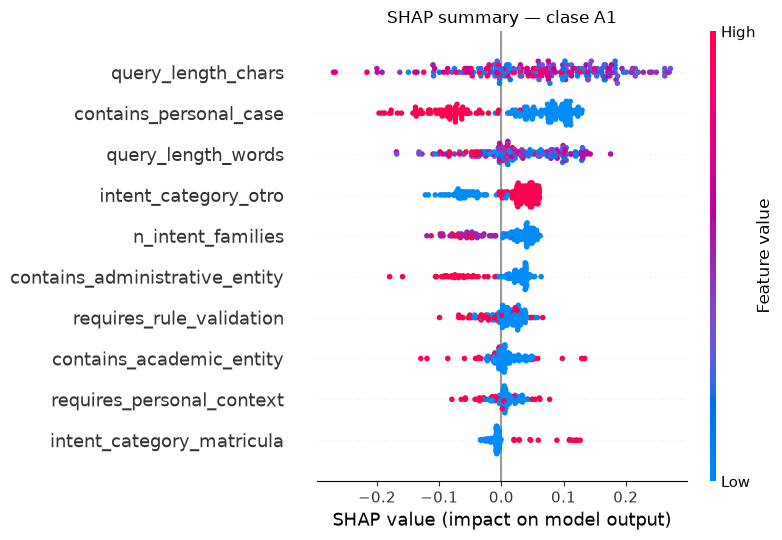

clase del summary: A1


In [6]:
import shap

# matriz ya transformada (numéricas + one-hot), alineada con feature_names
X_mat = pipe.named_steps["prep"].transform(X)
if hasattr(X_mat, "toarray"):
    X_mat = X_mat.toarray()

explainer = shap.TreeExplainer(pipe.named_steps["modelo"])
shap_values = explainer.shap_values(X_mat)

# Multiclass: lista/array por clase. Tomamos |SHAP| medio por feature (promedio entre clases).
if isinstance(shap_values, list):
    # lista de (n_samples, n_features)
    abs_mean = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
    classes = list(pipe.named_steps["modelo"].classes_)
    # summary de la clase A1 si existe
    if "A1" in classes:
        sv_plot = shap_values[classes.index("A1")]
        clase_plot = "A1"
    else:
        sv_plot = shap_values[0]
        clase_plot = str(classes[0])
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # (n_samples, n_features, n_classes)
    abs_mean = np.abs(shap_values).mean(axis=(0, 2))
    classes = list(pipe.named_steps["modelo"].classes_)
    if "A1" in classes:
        sv_plot = shap_values[:, :, classes.index("A1")]
        clase_plot = "A1"
    else:
        sv_plot = shap_values[:, :, 0]
        clase_plot = str(classes[0])
else:
    abs_mean = np.abs(shap_values).mean(axis=0)
    sv_plot = shap_values
    clase_plot = "salida"

imp_shap = pd.Series(abs_mean, index=feature_names).sort_values(ascending=False)
tabla_shap = imp_shap.head(TOP_N).rename("mean_abs_shap").reset_index()
tabla_shap.columns = ["feature", "mean_abs_shap"]
display(tabla_shap)

fig, ax = plt.subplots(figsize=(8, 4.5))
top_s = imp_shap.head(TOP_N).iloc[::-1]
ax.barh(top_s.index, top_s.values, color="#B279A2")
ax.set_xlabel("media de |SHAP| (promedio entre clases)")
ax.set_ylabel("feature")
ax.set_title("Top features por SHAP (TreeSHAP)")
ax.legend(["mean |SHAP|"], loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana7_importancia_shap_barras.png", dpi=150, bbox_inches="tight")
plt.show()

# summary plot clásico (beeswarm) para la clase A1
plt.figure()
shap.summary_plot(
    sv_plot,
    X_mat,
    feature_names=feature_names,
    max_display=TOP_N,
    show=False,
)
plt.title(f"SHAP summary — clase {clase_plot}")
plt.tight_layout()
plt.savefig(FIG_DIR / "semana7_importancia_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("clase del summary:", clase_plot)


## 6. Estabilidad entre pliegues

En cada pliegue se entrena un bosque y se guarda el top 5 por impureza.
Se cuenta cuántas veces aparece cada feature en ese top 5.


,pliegue,top5
0,1,"query_length_chars, query_length_words, contai..."
1,2,"query_length_chars, query_length_words, contai..."
2,3,"query_length_chars, query_length_words, contai..."
3,4,"query_length_chars, query_length_words, contai..."
4,5,"query_length_chars, query_length_words, contai..."


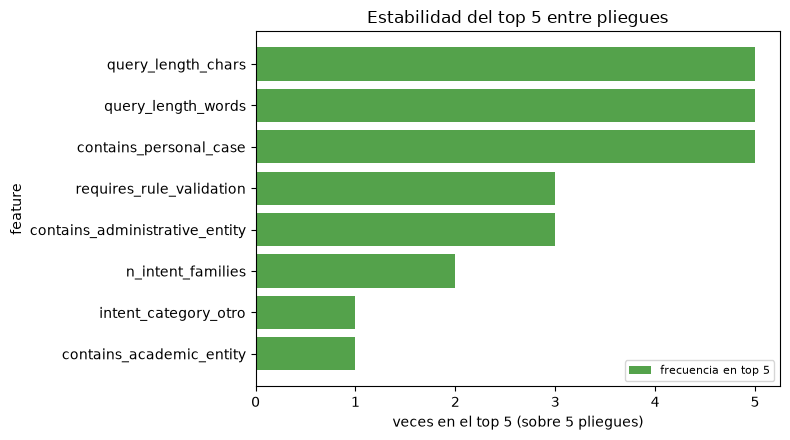

In [7]:
from collections import Counter

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
top5_por_fold = []
conteo = Counter()

for fold_id, (tr, te) in enumerate(cv.split(X, y), start=1):
    pipe_f = Pipeline(
        [
            (
                "prep",
                ColumnTransformer(
                    [
                        ("num", "passthrough", F1_NUM),
                        (
                            "cat",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                            F1_CAT,
                        ),
                    ]
                ),
            ),
            (
                "modelo",
                RandomForestClassifier(
                    n_estimators=300,
                    random_state=SEED,
                    class_weight="balanced",
                    n_jobs=-1,
                ),
            ),
        ]
    )
    pipe_f.fit(X.iloc[tr], y.iloc[tr])
    ohe_f = pipe_f.named_steps["prep"].named_transformers_["cat"]
    names_f = F1_NUM + list(ohe_f.get_feature_names_out(F1_CAT))
    series_f = pd.Series(
        pipe_f.named_steps["modelo"].feature_importances_,
        index=names_f,
    ).sort_values(ascending=False)
    top5 = list(series_f.head(5).index)
    top5_por_fold.append({"pliegue": fold_id, "top5": ", ".join(top5)})
    conteo.update(top5)

display(pd.DataFrame(top5_por_fold))

estab = pd.Series(conteo).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
top_e = estab.head(TOP_N).iloc[::-1]
ax.barh(top_e.index.astype(str), top_e.values, color="#54A24B")
ax.set_xlabel("veces en el top 5 (sobre 5 pliegues)")
ax.set_ylabel("feature")
ax.set_title("Estabilidad del top 5 entre pliegues")
ax.set_xticks(range(0, N_SPLITS + 1))
ax.legend(["frecuencia en top 5"], loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "semana7_importancia_estabilidad.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Interpretación y conclusión

- La impureza y SHAP se apoyan en la longitud, la permutación mas el caso personal 
- Las columnas que salen alto en más de un método y en varios pliegues, son las que más sentido tiene conservar dentro de F1.
- F1 se mantiene como paquete de trabajo. F0 no clasifica bien las rutas y F2, con BM25, no aporta algo significante


Nota: Se guarda un CSV en logs/ con el top de cada método, por si hay que repetir la corrida después.


In [8]:
# log corto para reproducibilidad
log = pd.DataFrame(
    {
        "metodo": ["impurity", "permutation", "shap_tree"],
        "modelo": ["RandomForestClassifier(n_estimators=300, class_weight=balanced)"] * 3,
        "conjunto": ["F1"] * 3,
        "etiqueta": [TARGET] * 3,
        "semilla": [SEED] * 3,
        "f1_macro_cv": [f"{f1_cv.mean():.3f} ± {f1_cv.std():.3f}"] * 3,
        "top1": [imp_gain.index[0], imp_perm.index[0], imp_shap.index[0]],
        "top1_valor": [float(imp_gain.iloc[0]), float(imp_perm.iloc[0]), float(imp_shap.iloc[0])],
    }
)
log.to_csv(LOG_DIR / "metrics_importancia_variables.csv", index=False)
imp_gain.to_csv(LOG_DIR / "importancia_impurity_full.csv", header=["importancia_impurity"])
imp_perm.to_csv(LOG_DIR / "importancia_permutacion_full.csv", header=["caida_f1_media"])
imp_shap.to_csv(LOG_DIR / "importancia_shap_full.csv", header=["mean_abs_shap"])
print("logs en", LOG_DIR)
print(log.to_string(index=False))


logs en /Users/cesarsanchez/Documents/04-archivo/01-educacion/01-universidad/1_FIIS_UNI/3_Term-III/Investigacion 1/Investigacion-Tesis/3_Sustentacion/3_entregable_curso_tesis/semana7/logs
     metodo                                                          modelo conjunto           etiqueta  semilla   f1_macro_cv                   top1  top1_valor
   impurity RandomForestClassifier(n_estimators=300, class_weight=balanced)       F1 candidate_strategy       42 0.553 ± 0.086     query_length_chars    0.371675
permutation RandomForestClassifier(n_estimators=300, class_weight=balanced)       F1 candidate_strategy       42 0.553 ± 0.086 contains_personal_case    0.077148
  shap_tree RandomForestClassifier(n_estimators=300, class_weight=balanced)       F1 candidate_strategy       42 0.553 ± 0.086     query_length_chars    0.109306
